# Ejercicio: asistente de documentos con NVIDIA NIM y Gradio

**Tiempo:** 40–45 minutos  
**Grupos:** 3–4 personas

## Contexto

En los notebooks anteriores construimos chatbots que responden preguntas
generales. En este ejercicio construiremos un asistente que responda preguntas
sobre un documento específico: **“Attention Is All You Need”**
(Vaswani et al., 2017).

Inyectar un documento completo en el contexto permite construir un primer
prototipo de *document question answering*. Esto ayuda a entender la motivación
de **RAG**, aunque todavía no es RAG: aquí no existe recuperación de fragmentos.

## Objetivo

Construir una aplicación Gradio donde el usuario pueda:

1. Cargar o leer el PDF del paper.
2. Hacer preguntas sobre su contenido.
3. Obtener respuestas basadas exclusivamente en el documento.

## Lo que van a aprender

- Extracción de texto de PDF con `pypdf`.
- Uso de contexto externo en un `system` prompt.
- Consumo de NVIDIA NIM mediante una API compatible con OpenAI.
- Streaming e historial con Gradio.
- Limitaciones de este enfoque y motivación de RAG.

## Paso 0: instalación y configuración

### 0.1 Instala las dependencias

- `pypdf`: extracción del texto del PDF.
- `gradio`: interfaz web.
- `openai`: cliente compatible con NVIDIA NIM.
- `python-dotenv`: lectura de variables de entorno.

```bash
pip install -q --upgrade pypdf gradio openai python-dotenv
```

In [1]:
!pip install -q --upgrade pypdf gradio openai python-dotenv

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 833.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 402.7/402.7 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 46.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 75.6 MB/s eta 0:00:00


### 0.2 Descarga el paper

Descarga el PDF abierto desde:

```text
https://arxiv.org/pdf/1706.03762
```

Guárdalo junto al notebook como `attention_is_all_you_need.pdf`.

### 0.3 Configura tus credenciales

Crea un archivo `.env` con tu API key de NVIDIA:

```text
NVIDIA_API_KEY="tu_key_aqui"
```

Puedes crearla en [NVIDIA Build](https://build.nvidia.com/settings/api-keys).

## Paso 1: extracción de texto del PDF

Lee el PDF y extrae su contenido como texto plano.

**Instrucciones:**

1. Importa `PdfReader` desde `pypdf`.
2. Crea `extract_text_from_pdf(pdf_path)`.
3. Abre el PDF e itera sobre `reader.pages`.
4. Concatena el resultado de `page.extract_text()`; contempla páginas sin texto.
5. Retorna el texto completo.
6. Prueba la función e imprime los primeros 500 caracteres.

> **Pista:** usa `page.extract_text() or ""` para evitar valores `None`.

In [28]:
from pypdf import PdfReader

def extract_text_from_pdf(pdf_path):
  reader = PdfReader(pdf_path) # Se carga el reader
  full_text = ""

  for page_number, page in enumerate(reader.pages, start=1):
        page_text = page.extract_text() or ""
        full_text += f"\n|PAGE #{page_number}\n{page_text}\n"

  return full_text

## Paso 2: inicialización del cliente de NVIDIA NIM

**Instrucciones:**

1. Importa `os`, `load_dotenv` y `OpenAI`.
2. Carga las variables con `load_dotenv()`.
3. Verifica que `NVIDIA_API_KEY` esté disponible sin imprimirla.
4. Inicializa `OpenAI` con:
   - `base_url="https://integrate.api.nvidia.com/v1"`
   - `api_key=os.getenv("NVIDIA_API_KEY")`
5. Define:

```python
MODELO = "nvidia/nemotron-3-super-120b-a12b"
```

In [10]:
import os, openai
from dotenv import load_dotenv

# Se carga el .env presente en la ruta del notebook
load_dotenv(".env")

base_url = "https://integrate.api.nvidia.com/v1"
api_key = ""
MODELO = "nvidia/nemotron-3-super-120b-a12b"

if "NVIDIA_API_KEY" in os.environ:
  api_key=os.getenv("NVIDIA_API_KEY")
else:
  raise Exception("NVIDIA API KEY not provided")



## Paso 3: función de chat con el documento

Construye un `system` prompt que incluya el texto del paper y obligue al modelo
a fundamentar sus respuestas en él.

**Instrucciones:**

1. Crea `build_system_prompt(document_text)` para:
   - definir al asistente como experto en el paper;
   - incluir el documento entre delimitadores claros;
   - exigir respuestas basadas únicamente en el documento;
   - indicar que responda “No encuentro esa información en el documento” cuando corresponda.

2. Crea `history_to_messages(history)` para convertir el historial de Gradio a
   mensajes con roles `user` y `assistant`.

3. Crea `chat_con_documento(message, history, document_text)` para:
   - iniciar `messages` con el `system` prompt;
   - agregar el historial y el mensaje actual;
   - llamar `client.chat.completions.create(..., stream=True)`;
   - acumular `chunk.choices[0].delta.content`;
   - usar `yield` para entregar la respuesta progresivamente.

> **Pista:** utiliza `temperature=1.0` y `top_p=0.95`, valores recomendados para
> Nemotron 3 Super.

In [11]:
from openai import OpenAI

# Inicializamos el cliente usando las variables definidas en la celda anterior
client = OpenAI(base_url=base_url, api_key=api_key)

def build_system_prompt(document_text):
    return f"""Eres un asistente experto en el paper académico proporcionado a continuación.

DOCUMENTO DE REFERENCIA:

---START DOCUMENT---
{document_text}
---END DOCUMENT---

Instrucciones estrictas:
1. Responde a las preguntas del usuario basándote únicamente en la información contenida en el documento de referencia anterior. Ademas, debes especificar de que pagina o paginas obtuviste la informacion. Cada pagina se encuentra denominada con PAGE #N
2. Si la información para responder a la pregunta no se encuentra en el documento, debes responder exactamente: \"No encuentro esa información en el documento\".
3. No utilices tu conocimiento general externo para responder sobre datos que no estén explícitamente en el texto proporcionado.
"""

def history_to_messages(history):
    messages = []
    for message in history:
        role = message.get("role")
        content = message.get("content")

        messages.append({"role": role, "content": content})

    return messages

def chat_con_documento(message, history, document_text):
    # 1. Crear el system prompt con el documento
    system_prompt = build_system_prompt(document_text)

    # 2. Construir la lista de mensajes empezando por el sistema
    messages = [{"role": "system", "content": system_prompt}]

    # 3. Agregar el historial de conversación transformado
    messages.extend(history_to_messages(history))

    # 4. Agregar la pregunta actual del usuario
    messages.append({"role": "user", "content": message})

    # 5. Llamada con streaming a la API
    response = client.chat.completions.create(
        model=MODELO,
        messages=messages,
        temperature=1.0,
        top_p=0.95,
        stream=True
    )

    # 6. Acumular y entregar la respuesta progresivamente
    partial_text = ""
    for chunk in response:
        if chunk.choices and chunk.choices[0].delta.content is not None:
            partial_text += chunk.choices[0].delta.content
            yield partial_text

## Paso 4: interfaz Gradio

Construye la interfaz con `gr.ChatInterface`.

**Instrucciones:**

1. Extrae el texto del PDF con la función del paso 1.
2. Muestra cuántas páginas y caracteres se extrajeron.
3. Configura `gr.ChatInterface` con:
   - `fn=chat_con_documento`;
   - un título y una descripción;
   - un `gr.Textbox` oculto dentro de `additional_inputs` para enviar el documento;
   - al menos tres preguntas de ejemplo.

```python
gr.Textbox(value=document_text, visible=False)
```

4. Lanza la interfaz:

```python
demo.launch(server_name="0.0.0.0", server_port=8080, show_error=True)
```

In [29]:
import gradio as gr

# Redefinimos la función de chat para que acepte la subida dinámica del archivo PDF
def chat_con_documento_dinamico(message, history, pdf_file):
    global document_text

    # 1. Si no se ha subido ningún archivo, advertimos al usuario
    if pdf_file is None:
        yield "Por favor, sube un archivo PDF primero utilizando el panel de carga de la izquierda."
        return

    try:
        # 2. Extraer el texto del PDF subido dinámicamente
        document_text = extract_text_from_pdf(pdf_file.name)
    except Exception as e:
        yield f"Error al leer el archivo PDF: {str(e)}"
        return

    # 3. Buscar las páginas relevantes para la pregunta
    contexto_relevante = buscar_paginas_relevantes(
        document_text,
        message,
        max_paginas=3
    )

    # 4. Verificar si se encontraron coincidencias
    if not contexto_relevante:
        yield "No encuentro esa información en el documento"
        return

    # 5. Crear el system prompt usando solo las páginas seleccionadas
    #system_prompt = build_system_prompt(document_text)
    system_prompt = build_system_prompt(contexto_relevante)

    # 6. Construir la lista de mensajes con el historial adaptado
    messages = [{"role": "system", "content": system_prompt}]
    messages.extend(history_to_messages(history))
    messages.append({"role": "user", "content": message})

    # 7. Llamada con streaming a la API de NVIDIA NIM
    response = client.chat.completions.create(
        model=MODELO,
        messages=messages,
        temperature=1.0,
        top_p=0.95,
        stream=True
    )

    # 8. Retorno progresivo de la respuesta
    partial_text = ""
    for chunk in response:
        if chunk.choices and chunk.choices[0].delta.content is not None:
            partial_text += chunk.choices[0].delta.content
            yield partial_text


# Configurar la interfaz de chat interactiva con la subida de archivos
ejemplos = [
    ["¿Cuál es la arquitectura principal propuesta en el paper?"],
    ["¿Qué es el mecanismo de atención?"],
    ["¿Qué es GPT-4?" ]
]

demo = gr.ChatInterface(
    fn=chat_con_documento_dinamico,
    title="Asistente de Documentos PDF Dinámico (NVIDIA NIM)",
    description="Sube cualquier archivo PDF a la izquierda y haz preguntas sobre su contenido en tiempo real.",
    additional_inputs=[
        gr.File(label="Sube tu archivo PDF aquí", file_types=[".pdf"], type="filepath")
    ],
    examples=ejemplos
)

# Lanzar la interfaz
demo.launch(server_name="0.0.0.0", show_error=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://989ca5c29a52930139.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Paso 5: Prueba y reflexión

Una vez que la interfaz esté funcionando, prueba estas preguntas:

1. *"¿Cuál es la arquitectura principal propuesta en el paper?"*
2. *"¿Qué es el mecanismo de atención?"*
3. *"¿Cuántas capas tiene el encoder del modelo base?"*
4. *"¿Quiénes son los autores del paper?"*
5. *"¿Cuál es el resultado del modelo en la tarea WMT 2014 English-to-German?"*

Y esta pregunta trampa:
6. *"¿Qué es GPT-4?"*

Esta última pregunta **no está en el paper**. Observa cómo responde el modelo.
¿Usa su conocimiento general o respeta la instrucción de ceñirse al documento?

<br><br>

**R:** Para la última pregunta, el modelo decidió respetar la instrucción de ceñirse netamente al documento. Por motivos de experimentación, se le preguntó sobre otros proyectos que los autores del paper realizaron. Para este, su respuesta demoró un poco más, pero mantuvo la misma respuesta:

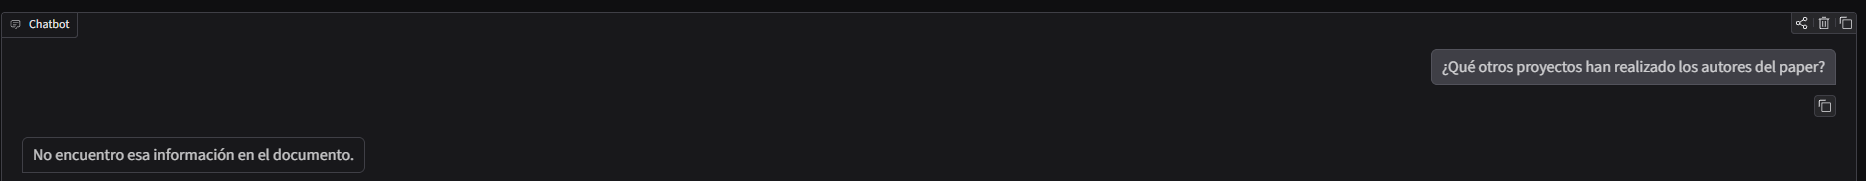

In [24]:
import tiktoken

# Obtener longitud en caracteres
num_caracteres = len(document_text)

# Obtener codificador estándar para estimar tokens de forma precisa
enc = tiktoken.get_encoding("cl100k_base")
tokens = enc.encode(document_text)
num_tokens = len(tokens)

print(f"Cantidad total de caracteres: {num_caracteres}")
print(f"Cantidad estimada de tokens: {num_tokens}")
print(f"Relación promedio (caracteres por token): {num_caracteres / num_tokens:.2f}")

Cantidad total de caracteres: 39585
Cantidad estimada de tokens: 10153
Relación promedio (caracteres por token): 3.90


## Paso 6 (adicional): mejora el sistema

Si terminan antes, implementen una mejora:

**A) Medición del contexto**  
Reporta la cantidad de caracteres o estima los tokens del documento. Explica
por qué caracteres y tokens no son equivalentes.

<br><br>

**R:** Según la celda anterior de código, utilizando la librería tiktoken, se reportan la siguiente cantidad de caracteres:

Cantidad total de caracteres: 39585 <br>
Cantidad estimada de tokens: 10153 <br>
Relación promedio (caracteres por token): 3.90 <br>

Caracteres y tokens no son equivalentes, ya que un caracter representa una unidad individual básica (algún numero, letra, signo), mientras que un token representa un bloque, el cuál puede estar conformado ya sea desde sílabas, partes de una palabra, hasta una palabra completa, la cual se utiliza como unidad de procesamiento para LLMs.

<br><br>

**B) Subida dinámica de PDF**  
Agrega `gr.File` para cargar cualquier PDF y extrae el texto dentro del flujo de
la aplicación.
<br><br>
![PDF dinamico](https://i.imgur.com/KD0WYVi.png)
<br><br>


**C) Evidencia y páginas**  
Conserva separadores de página al extraer el PDF y exige que cada respuesta cite
la página que contiene la evidencia.

<br><br>


**R:** Se crean separadores de página al final del texto extraido por pagina al final del contenido, agregando `|PAGE #N` donde N es el conteo que se lleva de las páginas.

Se modifica el prompt y ahora especifica la página donde obtuvo la información:

![Modificacion](https://i.imgur.com/t3mLXqg.png)

<br><br>

**D) Primer paso hacia RAG**  
Divide el documento en fragmentos y selecciona los más relevantes mediante una
búsqueda simple por palabras antes de llamar al modelo.

In [27]:
import re

def buscar_paginas_relevantes(documento_texto, mensaje_usuario, max_paginas=3):
    # Selecciona las páginas con más coincidencias con la pregunt y conserva el número original de cada página

    # Extraer el número y el contenido de cada página
    paginas = re.split(r"\|PAGE #(\d+)", documento_texto)

    # Preparar palabras clave
    palabras_clave = set(
        re.findall(r"\b[a-zA-ZáéíóúüñÁÉÍÓÚÜÑ]{4,}\b",
                   mensaje_usuario.lower())
    )

    if not palabras_clave:
        return ""

    puntajes = []

    # La estructura alterna: texto previo, número, contenido...
    for i in range(1, len(paginas), 2):
        numero_pagina = paginas[i]
        texto_pagina = paginas[i + 1]

        palabras_pagina = set(
            re.findall(r"\b[a-zA-ZáéíóúüñÁÉÍÓÚÜÑ]{4,}\b",
                       texto_pagina.lower())
        )

        score = len(palabras_clave & palabras_pagina)

        if score > 0:
            puntajes.append(
                (score, int(numero_pagina), texto_pagina.strip())
            )

    # Mayor puntuación primero
    puntajes.sort(key=lambda x: x[0], reverse=True)

    paginas_seleccionadas = puntajes[:max_paginas]

    # Si no hay coincidencias, no inventar contexto
    if not paginas_seleccionadas:
        return ""

    # Volver a incluir los números de página originales
    return "\n\n".join(
        f"|PAGE #{numero}\n{texto}"
        for score, numero, texto in paginas_seleccionadas
    )


Seleccionar páginas por coincidencia de palabras es un primer paso de RAG, pero no garantiza que sean las páginas semánticamente más relevantes. Primeramente priorizamos que la recuperación funcione correctamente y que el modelo no reciba automáticamente el documento completo cuando no encuentra coincidencias.

Sin embargo, observaos que nuestra implementación limita el modelo debido a que es muy literal, si no encuentra palabras literales de coincidencia entre la pregunta y el texto lo toma como si no existiera información de este, no es interpretable. Esto lo podríamos mejorar usando una combinación de ambos modelos: cuando no hay páginas con contexto relevante podríamos pasarle todo el PDF para que el modelo se alimente y tenga contexto interpretable, aunque estaríamos yendo en contra de las ventajas del RAG.

Ejemplos usando estrictamente RAG:

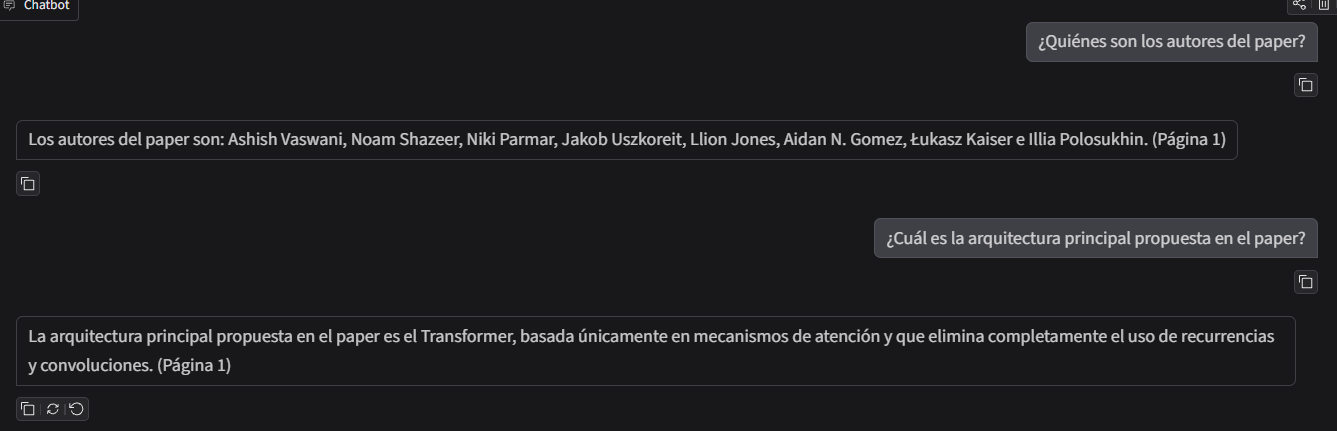

## Reflexión final

Discutan en grupo:

1. ¿Cuál es la limitación de enviar siempre el documento completo?

    R= Enviar el documento completo en cada consulta aumenta el consumo de tokens, el costo y el tiempo de procesamiento. Además, los modelos tienen una ventana de contexto limitada, por lo que los documentos grandes pueden superar su capacidad o dificultar que identifiquen la información más relevante, lo fomenta la creación de alucinaciones

2. ¿Por qué este ejercicio todavía no implementa RAG?

    R= La versión inicial no implementa RAG porque incluye el documento completo directamente en el prompt, sin recuperar fragmentos según la pregunta del usuario.

    Con la mejora del punto D, se implementa una aproximación básica a RAG, ya que se recuperan fragmentos relevantes antes de generar la respuesta. Sin embargo, utiliza una búsqueda simple por palabras, en lugar de técnicas semánticas más avanzadas.

3. ¿Cómo comprobarían que la respuesta proviene del documento y no del
   conocimiento previo del modelo?

    R= Se pueden comparar las respuestas con el contenido original, exigir citas de las páginas correspondientes y comprobar que la evidencia citada respalde realmente cada afirmación. También se pueden realizar preguntas sobre información que no aparece en el documento y verificar que el modelo indique que no encuentra esa información.
   
4. ¿Qué riesgos aparecen al insertar directamente documentos de usuarios en el
   prompt?

    R= Los documentos pueden contener instrucciones maliciosas que intenten manipular el comportamiento del modelo (prompt injection). También pueden incluir información confidencial, contenido engañoso o texto irrelevante que afecte las respuestas.

## Recursos

- [pypdf](https://pypdf.readthedocs.io)
- [Gradio](https://www.gradio.app/docs)
- [NVIDIA Build](https://build.nvidia.com)
- [Nemotron 3 Super](https://build.nvidia.com/nvidia/nemotron-3-super-120b-a12b)
- [Paper original](https://arxiv.org/abs/1706.03762)